In [6]:
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Visualization styling
sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams["figure.figsize"] = (11, 5)
pd.set_option("display.max_colwidth", 90)

In [3]:
# Load the District Kulgam CPGRAMS synthetic dataset
file_path = "cpgrams_synthetic_grievances_kulgam_500.csv"
df = pd.read_csv(file_path)

print(f"Dataset Shape: {df.shape[0]} rows × {df.shape[1]} columns\n")
display(df.head(5))
df.info()

Dataset Shape: 500 rows × 13 columns



,Grievance_ID,Date,Grievance,Grievance_Category,Pertaining_Department_Office,Priority,Status,District,Tehsil,Submission_Channel,Relevant_Scheme_Guideline,Resolution_Days,Officer_Remarks
0,CPGRAMS-KLG-2023-0001,2023-11-20,"Choked open drains in Village Buchroo, Frisal ...",Development Related,Municipal Council / ULB Kulgam,Medium,Resolved,Kulgam,Frisal,JK-IGRAMS Portal,Swachh Bharat Mission (Urban) / Urban Infra,43.0,Municipal hopper vehicle assigned for daily do...
1,CPGRAMS-KLG-2023-0002,2023-11-21,Doctor and paramedical staff are frequently ab...,Complaint Related,CMO (Health),High,Resolved,Kulgam,Devsar,Mobile App,NHM / Ayushman Bharat (PM-JAY SEHAT),20.0,BMO conducted inspection; biometric attendance...
2,CPGRAMS-KLG-2023-0003,2023-11-22,Unlawful blockage of a common public pathway b...,Magisterial,ADC / ACR (Administration),Medium,Resolved,Kulgam,Frisal,CPGRAMS Web Portal,BNSS / Section 133 Public Nuisance & Magisteri...,45.0,Market checking squad fined erring shopkeepers...
3,CPGRAMS-KLG-2023-0004,2023-11-25,"To the Deputy Commissioner Kulgam, Frequent tr...",Others,ADC / ACR (Administration),Medium,Resolved,Kulgam,Pahloo,CPGRAMS Web Portal,General Public Service / Transport & Connectivity,34.0,Special Aadhaar update camp organized at Panch...
4,CPGRAMS-KLG-2023-0005,2023-11-27,"Private school in Village Waltengoo Nar, Kund ...",Complaint Related,CEO (Education),Medium,Resolved,Kulgam,Devsar,CPGRAMS Web Portal,Samagra Shiksha / RTE Act,23.0,Subject teachers rationalized and deployed to ...


<class 'pandas.DataFrame'>
RangeIndex: 500 entries, 0 to 499
Data columns (total 13 columns):
 #   Column                        Non-Null Count  Dtype  
---  ------                        --------------  -----  
 0   Grievance_ID                  500 non-null    str    
 1   Date                          500 non-null    str    
 2   Grievance                     500 non-null    str    
 3   Grievance_Category            500 non-null    str    
 4   Pertaining_Department_Office  500 non-null    str    
 5   Priority                      500 non-null    str    
 6   Status                        500 non-null    str    
 7   District                      500 non-null    str    
 8   Tehsil                        500 non-null    str    
 9   Submission_Channel            500 non-null    str    
 10  Relevant_Scheme_Guideline     500 non-null    str    
 11  Resolution_Days               399 non-null    float64
 12  Officer_Remarks               500 non-null    str    
dtypes: float64(1), s

In [4]:
# Separate columns by Big Data data-type paradigm
structured_cols = [
    "Grievance_ID",
    "Date",
    "Grievance_Category",
    "Pertaining_Department_Office",
    "Priority",
    "Status",
    "District",
    "Tehsil",
    "Submission_Channel",
    "Relevant_Scheme_Guideline",
    "Resolution_Days"
]

unstructured_cols = [
    "Grievance",
    "Officer_Remarks"
]

print("STRUCTURED COLUMNS (Fixed schema, tabular/categorical/numerical):")
for col in structured_cols:
    print(f"  - {col} ({df[col].dtype}) | Unique values: {df[col].nunique()}")

print("\nUNSTRUCTURED COLUMNS (Free-form natural language text):")
for col in unstructured_cols:
    avg_words = df[col].dropna().astype(str).str.split().str.len().mean()
    print(f"  - {col} ({df[col].dtype}) | Avg word count: {avg_words:.1f} words")

STRUCTURED COLUMNS (Fixed schema, tabular/categorical/numerical):
  - Grievance_ID (str) | Unique values: 500
  - Date (str) | Unique values: 403
  - Grievance_Category (str) | Unique values: 6
  - Pertaining_Department_Office (str) | Unique values: 13
  - Priority (str) | Unique values: 3
  - Status (str) | Unique values: 2
  - District (str) | Unique values: 1
  - Tehsil (str) | Unique values: 7
  - Submission_Channel (str) | Unique values: 5
  - Relevant_Scheme_Guideline (str) | Unique values: 16
  - Resolution_Days (float64) | Unique values: 52

UNSTRUCTURED COLUMNS (Free-form natural language text):
  - Grievance (str) | Avg word count: 30.0 words
  - Officer_Remarks (str) | Avg word count: 10.6 words


In [7]:
# 1. Inspect missing values before cleaning
print("Missing values per column (Before Cleaning):")
print(df.isnull().sum()[df.isnull().sum() > 0])

# Convert Date to datetime and Resolution_Days to numeric
df["Date"] = pd.to_datetime(df["Date"], errors="coerce")
df["Resolution_Days"] = pd.to_numeric(df["Resolution_Days"], errors="coerce")

# - Text columns: fill any NaN with empty string
df["Grievance"] = df["Grievance"].fillna("")
df["Officer_Remarks"] = df["Officer_Remarks"].fillna("No remarks recorded")

# - Categorical columns: fill any unexpected NaN with 'Unknown'
cat_cols = ["Grievance_Category", "Pertaining_Department_Office", "Priority", "Status", "Tehsil"]
for col in cat_cols:
    df[col] = df[col].fillna("Unknown").str.strip()

# - Resolution_Days: NaN is structurally valid for 'Pending' grievances.
#   We keep NaN for Pending rows so average resolution time isn't distorted by 0s,
df["Is_Resolved"] = np.where(df["Status"] == "Resolved", 1, 0)

# 2. Clean unstructured text (remove special characters & extra whitespace)
def clean_text(text):
    text = str(text)
    text = re.sub(r"[^a-zA-Z0-9\s]", " ", text)   # remove special characters/punctuation
    text = re.sub(r"\s+", " ", text).strip()      # collapse multiple spaces
    return text

df["Grievance_Clean"] = df["Grievance"].apply(clean_text)
df["Officer_Remarks_Clean"] = df["Officer_Remarks"].apply(clean_text)

print("\nMissing values per column (After Cleaning):")
print(df.isnull().sum()[df.isnull().sum() > 0])

print("\nSample Before vs. After Text Cleaning:")
display(df[["Grievance", "Grievance_Clean"]].head(3))

Missing values per column (Before Cleaning):
Resolution_Days    101
dtype: int64

Missing values per column (After Cleaning):
Resolution_Days    101
dtype: int64

Sample Before vs. After Text Cleaning:


,Grievance,Grievance_Clean
0,"Choked open drains in Village Buchroo, Frisal are overflowing onto the main street. Sa...",Choked open drains in Village Buchroo Frisal are overflowing onto the main street Sani...
1,Doctor and paramedical staff are frequently absent during night shift at the Primary H...,Doctor and paramedical staff are frequently absent during night shift at the Primary H...
2,"Unlawful blockage of a common public pathway by a local resident in Village Nagam, Fri...",Unlawful blockage of a common public pathway by a local resident in Village Nagam Fris...


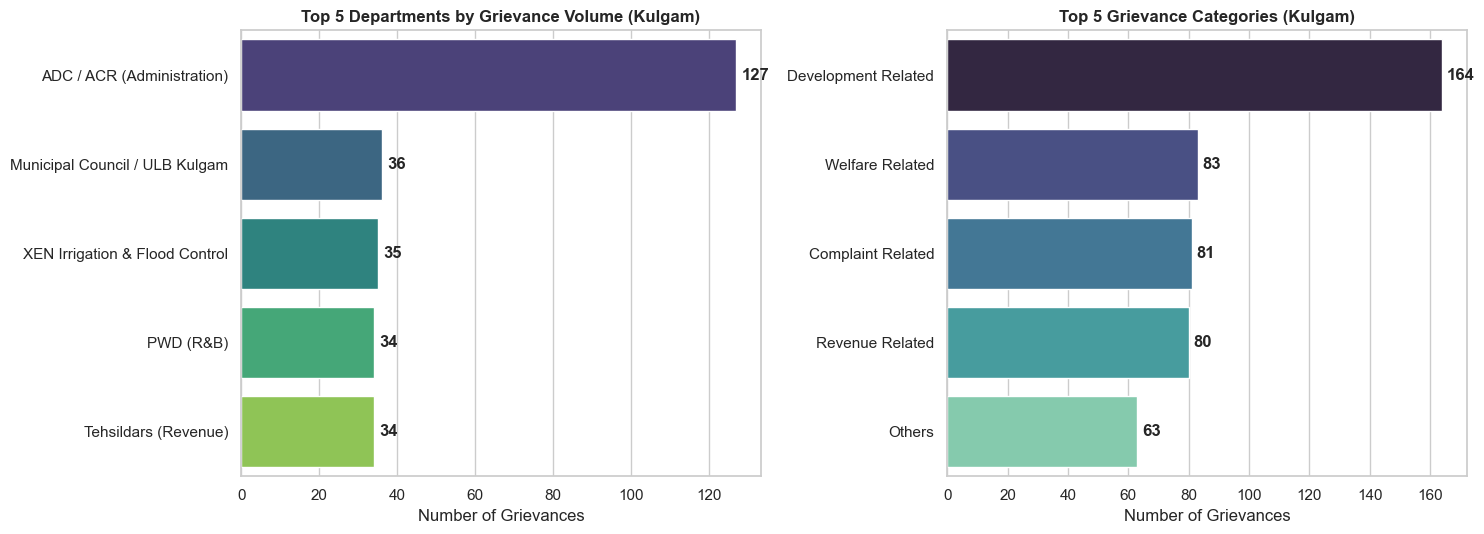

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))

# Subplot 1: Top 5 Pertaining Departments
top5_depts = df["Pertaining_Department_Office"].value_counts().head(5)
sns.barplot(
    x=top5_depts.values,
    y=top5_depts.index,
    hue=top5_depts.index,
    palette="viridis",
    legend=False,
    ax=axes[0]
)
axes[0].set_title("Top 5 Departments by Grievance Volume (Kulgam)", fontsize=12, fontweight="bold")
axes[0].set_xlabel("Number of Grievances")
axes[0].set_ylabel("")
for i, v in enumerate(top5_depts.values):
    axes[0].text(v + 1.5, i, str(v), va="center", fontweight="bold")

# Subplot 2: Top 5 Grievance Categories
top5_cats = df["Grievance_Category"].value_counts().head(5)
sns.barplot(
    x=top5_cats.values,
    y=top5_cats.index,
    hue=top5_cats.index,
    palette="mako",
    legend=False,
    ax=axes[1]
)
axes[1].set_title("Top 5 Grievance Categories (Kulgam)", fontsize=12, fontweight="bold")
axes[1].set_xlabel("Number of Grievances")
axes[1].set_ylabel("")
for i, v in enumerate(top5_cats.values):
    axes[1].text(v + 1.5, i, str(v), va="center", fontweight="bold")

plt.tight_layout()
plt.show()

In [10]:
df.to_csv("cpgrams_kulgam_cleaned.csv", index=False)
print("Saved cleaned dataset to 'cpgrams_kulgam_cleaned.csv'")

Saved cleaned dataset to 'cpgrams_kulgam_cleaned.csv'
